# ClimaCity Paris -- 04. Structured Streaming (Jour 2 après-midi)

Ce carnet traite un **flux simulé** de relevés Vélib' en temps quasi réel :

1. préparation, avec Spark, d'une matinée à rejouer, extraite de la table Delta `disponibilite` ;
2. le **simulateur** (`scripts/simulateur_flux.py`) dépose les passages du collecteur un par un, en
   fichiers JSON, dans un répertoire surveillé ;
3. une source `readStream` avec un **schéma explicite**, et un **watermark** pour borner l'attente des
   données tardives ;
4. deux agrégations sur une **fenêtre glissante de 10 minutes avançant toutes les 2 minutes** : vélos
   disponibles par arrondissement (sink Delta en mode *append*), et état de chaque station ;
5. une table **`alertes`** : station sans aucun vélo sur deux fenêtres consécutives ;
6. la **donnée tardive** : un passage en retard d'un quart d'heure est accepté, un passage en retard
   d'une heure est rejeté. On le prouve de façon déterministe (`processAllAvailable`, puis
   `numRowsDroppedByWatermark`, puis comparaison avec le même calcul en batch).

Le carnet ne lit que la table Delta `disponibilite` écrite par le carnet 03.

## 1. Session et dossiers du flux

On garde jusqu'à 1 000 rapports de progression par requête (100 par défaut), pour pouvoir relire
tous les micro-lots après coup. Les dossiers du flux (fichiers d'entrée, checkpoints) et les tables
Delta qu'il produit sont vidés au départ : un checkpoint d'une exécution précédente ferait reprendre
le flux là où il s'était arrêté, et le carnet ne serait plus rejouable.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..", "scripts").resolve()))
from config import *          # chemins, SEED, SHUFFLE_PARTITIONS, creer_session()

import json
import shutil
import subprocess
import time
from datetime import timedelta

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import functions as F
from pyspark.sql.types import (DoubleType, IntegerType, StringType, StructField, StructType,
                               TimestampType)
from pyspark.sql.window import Window

from simulateur_flux import ordre_emission

spark = creer_session("ClimaCity-04-streaming", spark__sql__streaming__numRecentProgressUpdates="1000")
sc = spark.sparkContext

REJEU = STREAM / "rejeu"                    # passages préparés (lus par le simulateur)
ENTREE = STREAM / "entree"                  # répertoire surveillé par readStream
CHECKPOINTS = STREAM / "checkpoints"
DELTA_FLUX_ARRONDISSEMENTS = DELTA / "flux_arrondissements"
DELTA_FLUX_STATIONS = DELTA / "flux_stations"
DELTA_ALERTES = DELTA / "alertes"

for dossier in [STREAM, DELTA_FLUX_ARRONDISSEMENTS, DELTA_FLUX_STATIONS, DELTA_ALERTES]:
    shutil.rmtree(dossier, ignore_errors=True)
ENTREE.mkdir(parents=True)
print("Spark", spark.version, "| Spark UI :", sc.uiWebUrl)

Spark 3.5.3 | Spark UI : http://b7268ef2058c:4040


## 2. La matinée à rejouer

Le simulateur rejoue des **données historiques** : il faut d'abord choisir lesquelles. Tous les relevés
d'un même passage du collecteur partagent le même horodatage. On retient le **jeudi 25 mars 2021, de
4 h à 11 h UTC** (de 5 h à midi à Paris, encore à l'heure d'hiver) :

- c'est un jour ouvré, avec la pointe du matin, avant le confinement du 3 avril ;
- fin mars, le collecteur passe plus souvent qu'en hiver : environ toutes les 15 minutes (jusqu'à
  50 minutes en janvier), ce qui donne un flux régulier.

On numérote les passages avec `dense_rank`, puis on écrit **un dossier JSON par passage**
(`partitionBy("passage")`). Le `repartition("passage")` envoie chaque passage dans une seule tâche, donc
un seul fichier par dossier : c'est ce que le simulateur recopiera.

In [2]:
DEBUT_REJEU, FIN_REJEU = "2021-03-25 04:00:00", "2021-03-25 11:00:00"     # UTC
COLONNES_FLUX = ["station_id", "nom_station", "arrondissement", "latitude", "longitude", "horodatage",
                 "velos_mecaniques", "velos_electriques", "bornettes_libres", "capacite_totale"]

rejeu = (spark.read.format("delta").load(str(DELTA_DISPONIBILITE))
         .filter((F.col("horodatage") >= DEBUT_REJEU) & (F.col("horodatage") < FIN_REJEU))
         .select(*COLONNES_FLUX)
         # une seule journée : la partition par date évite de tout ramener dans une partition unique
         .withColumn("passage", F.dense_rank().over(
             Window.partitionBy(F.to_date("horodatage")).orderBy("horodatage")) - 1))

sc.setJobDescription("écriture des passages à rejouer")
(rejeu.repartition("passage").sortWithinPartitions("station_id")
 .write.partitionBy("passage").json(str(REJEU)))
sc.setJobDescription(None)

passages = (spark.read.json(str(REJEU)).groupBy("passage")
            .agg(F.min("horodatage").alias("horodatage"), F.count("*").alias("releves"),
                 F.sum(F.expr("int(velos_mecaniques + velos_electriques = 0)")).alias("stations_vides"))
            .orderBy("passage").toPandas())                      # 28 lignes
passages["horodatage"] = pd.to_datetime(passages["horodatage"], utc=True)
passages["ecart_min"] = passages["horodatage"].diff().dt.total_seconds() / 60
HORAIRES = dict(zip(passages["passage"], passages["horodatage"]))   # {passage: horodatage UTC}

print(f"{len(passages)} passages, {passages['releves'].sum():,} relevés".replace(",", " "),
      f"| écart entre passages : {passages['ecart_min'].min():.0f} à {passages['ecart_min'].max():.0f} min")
print(len(list(REJEU.glob("passage=*/part-*.json"))), "fichiers JSON écrits")
passages.assign(horodatage=passages["horodatage"].dt.strftime("%H:%M")).set_index("passage").T

28 passages  38 276 relevés | écart entre passages : 12 à 17 min
28 fichiers JSON écrits


passage,0,1,2,3,4,5,6,7,8,9,...,18,19,20,21,22,23,24,25,26,27
horodatage,04:07,04:19,04:36,04:51,05:07,05:19,05:36,05:50,06:06,06:19,...,08:35,08:49,09:04,09:19,09:35,09:49,10:05,10:19,10:35,10:50
releves,1367,1367,1367,1367,1367,1367,1367,1367,1367,1367,...,1367,1367,1367,1367,1367,1367,1367,1367,1367,1367
stations_vides,18,19,17,15,16,15,8,10,9,8,...,33,29,34,40,41,38,39,41,37,41
ecart_min,NaN,12.0,17.0,15.0,16.0,12.0,17.0,14.0,16.0,13.0,...,16.0,14.0,15.0,15.0,16.0,14.0,16.0,14.0,16.0,15.0


## 3. Le simulateur et le scénario de retard

`scripts/simulateur_flux.py` joue le rôle du micro-service de l'énoncé. Il ne fait aucun calcul : il
recopie les passages dans le répertoire surveillé, un toutes les 2 secondes (une matinée de 7 heures
rejouée en une minute, soit environ 450 fois plus vite). Chaque fichier est écrit sous un nom caché puis
**renommé**, ce qui est atomique : Spark, qui ignore les fichiers commençant par `.`, ne lit jamais un
fichier à moitié écrit.

L'option `--retard P:N` retient le passage `P` jusqu'à ce que les `N` passages suivants soient émis.
Les horodatages (l'**heure de l'événement**) ne changent pas : seul l'**ordre d'arrivée** change, comme
lorsqu'un capteur remonte ses mesures avec du retard. Le scénario :

- passage **12** (7 h 05 UTC) retenu **1 passage** : il arrive environ un quart d'heure trop tard ;
- passage **18** (8 h 35 UTC) retenu **4 passages** : il arrive environ une heure trop tard.

Le **watermark** est fixé à **20 minutes** : Spark attend les données jusqu'à 20 minutes derrière
l'horodatage le plus récent déjà vu. C'est un peu plus que l'écart entre deux passages (au plus
17 minutes ce matin-là) : un passage en retard d'un cran doit être accepté, un passage en retard de
quatre crans doit être rejeté. Les `assert` vérifient que les horaires réels du rejeu le garantissent.

In [3]:
WATERMARK = timedelta(minutes=20)
FENETRE, GLISSEMENT = timedelta(minutes=10), timedelta(minutes=2)
RETARDS = {12: 1, 18: 4}                       # {passage retenu: passages émis avant lui}
PASSAGE_TOLERE, PASSAGE_REJETE = 12, 18

ordre = ordre_emission(list(HORAIRES), RETARDS)
print("Ordre d'arrivée :", ordre)

# Passage 12 : quand il arrive, le passage le plus récent déjà vu est le 13.
# Le watermark vaut alors horaire(13) - 20 min, encore antérieur à l'horaire du passage 12.
vu_avant_tolere = max(ordre[:ordre.index(PASSAGE_TOLERE)])
assert HORAIRES[vu_avant_tolere] - WATERMARK < HORAIRES[PASSAGE_TOLERE]

# Passage 18 : le watermark (horaire(22) - 20 min) a dépassé la FIN de toutes les fenêtres qui
# contiennent son horaire (au plus horaire(18) + 10 min).
vu_avant_rejete = max(ordre[:ordre.index(PASSAGE_REJETE)])
assert HORAIRES[vu_avant_rejete] - WATERMARK > HORAIRES[PASSAGE_REJETE] + FENETRE

for p, vu in [(PASSAGE_TOLERE, vu_avant_tolere), (PASSAGE_REJETE, vu_avant_rejete)]:
    print(f"passage {p} ({HORAIRES[p]:%H:%M}) : arrive après le passage {vu} ({HORAIRES[vu]:%H:%M}), "
          f"watermark alors à {HORAIRES[vu] - WATERMARK:%H:%M}")

Ordre d'arrivée : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 12, 14, 15, 16, 17, 19, 20, 21, 22, 18, 23, 24, 25, 26, 27]
passage 12 (07:05) : arrive après le passage 13 (07:20), watermark alors à 07:00
passage 18 (08:35) : arrive après le passage 22 (09:35), watermark alors à 09:15


## 4. Source de streaming avec un schéma explicite

Une source fichier en streaming **exige** un schéma : Spark ne peut pas lire tout le répertoire pour
l'inférer, puisque les fichiers n'existent pas encore au démarrage (l'inférence existe en option, mais
elle ne voit que les fichiers déjà présents et fige le schéma au premier lancement). Le schéma explicite
garantit aussi les types : `horodatage` est lu comme `TimestampType` depuis la chaîne ISO 8601
(`2021-03-25T07:05:00.000Z`).

`maxFilesPerTrigger = 1` fait traiter **un fichier, donc un passage, par micro-lot**, dans l'ordre
d'arrivée. Le watermark avance donc passage après passage, quel que soit le rythme du simulateur ou la
vitesse de Spark : c'est ce qui rend le scénario de retard **déterministe**.

In [4]:
SCHEMA_FLUX = StructType([
    StructField("station_id", IntegerType()),
    StructField("nom_station", StringType()),
    StructField("arrondissement", IntegerType()),
    StructField("latitude", DoubleType()),
    StructField("longitude", DoubleType()),
    StructField("horodatage", TimestampType()),
    StructField("velos_mecaniques", IntegerType()),
    StructField("velos_electriques", IntegerType()),
    StructField("bornettes_libres", IntegerType()),
    StructField("capacite_totale", IntegerType()),
])

flux = (spark.readStream.schema(SCHEMA_FLUX)
        .option("maxFilesPerTrigger", 1)
        .json(str(ENTREE)))
releves_flux = (flux
                .withColumn("velos_disponibles", F.col("velos_mecaniques") + F.col("velos_electriques"))
                .withWatermark("horodatage", "20 minutes"))

print("isStreaming :", releves_flux.isStreaming)
releves_flux.printSchema()

isStreaming : True
root
 |-- station_id: integer (nullable = true)
 |-- nom_station: string (nullable = true)
 |-- arrondissement: integer (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- horodatage: timestamp (nullable = true)
 |-- velos_mecaniques: integer (nullable = true)
 |-- velos_electriques: integer (nullable = true)
 |-- bornettes_libres: integer (nullable = true)
 |-- capacite_totale: integer (nullable = true)
 |-- velos_disponibles: integer (nullable = true)



## 5. Agrégations sur fenêtre glissante

`window("horodatage", "10 minutes", "2 minutes")` range chaque relevé dans les **cinq fenêtres** de
10 minutes qui le contiennent (une nouvelle fenêtre commence toutes les 2 minutes). Les deux
agrégations sont écrites comme des fonctions : le **même code** s'applique au flux et, plus bas, à un
DataFrame batch, pour vérifier le résultat du streaming.

Les passages étant espacés d'au moins 12 minutes, une fenêtre de 10 minutes contient **au plus un
passage**. Par prudence, le nombre de vélos par arrondissement est divisé par le nombre de passages de
la fenêtre (`approx_count_distinct`, exact sur d'aussi petits effectifs) : c'est le nombre moyen de
vélos disponibles à un passage, qui ne double pas si deux passages tombaient dans la même fenêtre.

In [5]:
def fenetres_arrondissement(releves):
    """Agrège les relevés par arrondissement sur une fenêtre glissante de 10 minutes.

    Args:
        releves: DataFrame (batch ou streaming) au schéma ``SCHEMA_FLUX`` plus ``velos_disponibles``.

    Returns:
        Un DataFrame avec une ligne par (fenêtre, arrondissement) : début et fin de la fenêtre,
        nombre moyen de vélos disponibles par passage, relevés, passages et stations vides.

    Example:
        >>> fenetres_arrondissement(releves_flux).isStreaming
        True
    """
    return (releves
            .groupBy(F.window("horodatage", "10 minutes", "2 minutes").alias("fenetre"), "arrondissement")
            .agg(F.sum("velos_disponibles").alias("velos_cumules"),
                 F.count("*").alias("releves"),
                 F.approx_count_distinct("horodatage").alias("passages"),
                 F.sum(F.expr("int(velos_disponibles = 0)")).alias("releves_vides"))
            .select(F.col("fenetre.start").alias("fenetre_debut"), F.col("fenetre.end").alias("fenetre_fin"),
                    "arrondissement",
                    (F.col("velos_cumules") / F.col("passages")).alias("velos_disponibles"),
                    "releves", "passages", "releves_vides"))


def fenetres_station(releves):
    """Résume l'état de chaque station sur une fenêtre glissante de 10 minutes.

    Args:
        releves: DataFrame (batch ou streaming) au schéma ``SCHEMA_FLUX`` plus ``velos_disponibles``.

    Returns:
        Un DataFrame avec une ligne par (fenêtre, station) ayant au moins un relevé : vélos
        disponibles minimum et maximum, nombre de relevés et horodatage du dernier relevé.

    Example:
        >>> fenetres_station(releves_flux).columns[:3]
        ['fenetre_debut', 'fenetre_fin', 'station_id']
    """
    return (releves
            .groupBy(F.window("horodatage", "10 minutes", "2 minutes").alias("fenetre"),
                     "station_id", "nom_station", "arrondissement")
            .agg(F.min("velos_disponibles").alias("velos_min"),
                 F.max("velos_disponibles").alias("velos_max"),
                 F.count("*").alias("releves"),
                 F.max("horodatage").alias("dernier_releve"))
            .select(F.col("fenetre.start").alias("fenetre_debut"), F.col("fenetre.end").alias("fenetre_fin"),
                    "station_id", "nom_station", "arrondissement",
                    "velos_min", "velos_max", "releves", "dernier_releve"))


fenetres_arrondissement(releves_flux).printSchema()

root
 |-- fenetre_debut: timestamp (nullable = true)
 |-- fenetre_fin: timestamp (nullable = true)
 |-- arrondissement: integer (nullable = true)
 |-- velos_disponibles: double (nullable = true)
 |-- releves: long (nullable = false)
 |-- passages: long (nullable = false)
 |-- releves_vides: long (nullable = true)



## 6. La table `alertes`

**ADAPTATION.** L'énoncé demande une alerte quand une station n'a plus aucun vélo sur **deux fenêtres
consécutives**. Avec un glissement de 2 minutes, deux fenêtres qui se suivent se recouvrent sur
8 minutes et contiennent presque toujours **le même relevé** : un seul relevé à zéro déclencherait
l'alerte, ce qui n'est pas l'intention (repérer une rupture qui dure). On prend donc deux fenêtres
**consécutives sans recouvrement** : la fenêtre `[t, t + 10 min)` et celle qui la précède immédiatement,
`[t - 10 min, t)`, toutes deux de la série glissante. Les deux doivent contenir un relevé, avec zéro vélo :
la station est vide à **deux passages successifs** du collecteur, soit environ un quart d'heure.

L'alerte compare des fenêtres **finalisées** : en mode *append*, une fenêtre n'est émise qu'une fois
que le watermark a dépassé sa fin, et n'est plus jamais modifiée. La fenêtre précédente finit avant la
fenêtre courante : elle est toujours émise dans le même micro-lot ou dans un lot antérieur.

Comme Spark n'enchaîne pas une jointure sur le résultat d'une agrégation en streaming, l'état des
stations passe par `foreachBatch`. Pour chaque micro-lot :

1. les fenêtres finalisées sont ajoutées à la table Delta `flux_stations`. Les options
   `txnAppId` / `txnVersion` rendent l'écriture **idempotente** : si un lot est rejoué après une
   panne, Delta reconnaît son numéro et ne l'écrit pas deux fois ;
2. les fenêtres vides du lot sont jointes à `flux_stations` pour retrouver la fenêtre précédente ;
3. les alertes sont ajoutées à `alertes` par un `MERGE` sur `(station_id, second_releve_vide)`, lui aussi
   idempotent. Plusieurs paires de fenêtres peuvent confirmer le même relevé : on n'en garde qu'une.

In [6]:
SCHEMA_ALERTES = StructType([
    StructField("station_id", IntegerType()),
    StructField("nom_station", StringType()),
    StructField("arrondissement", IntegerType()),
    StructField("premier_releve_vide", TimestampType()),
    StructField("second_releve_vide", TimestampType()),
    StructField("fenetre_confirmation", TimestampType()),
    StructField("declenchee_a", TimestampType()),
])
spark.createDataFrame([], SCHEMA_ALERTES).write.format("delta").save(str(DELTA_ALERTES))


def traiter_lot_stations(lot, id_lot):
    """Écrit un micro-lot de fenêtres de stations et en déduit les nouvelles alertes.

    Args:
        lot: Fenêtres finalisées du micro-lot (DataFrame batch produit par ``fenetres_station``).
        id_lot: Numéro du micro-lot, fourni par Spark ; sert de version de transaction Delta.

    Returns:
        None. Les fenêtres sont ajoutées à ``flux_stations``, les alertes à ``alertes``.

    Example:
        >>> fenetres_station(releves_flux).writeStream.foreachBatch(traiter_lot_stations)  # doctest: +SKIP
    """
    lot.persist()
    (lot.write.format("delta").mode("append")
     .option("txnAppId", "flux_stations").option("txnVersion", id_lot)
     .save(str(DELTA_FLUX_STATIONS)))

    session = lot.sparkSession
    vides = session.read.format("delta").load(str(DELTA_FLUX_STATIONS)).filter("velos_max = 0")
    nouvelles = (lot.filter("velos_max = 0").alias("c")
                 .join(vides.alias("p"),
                       (F.col("p.station_id") == F.col("c.station_id"))
                       & (F.col("p.fenetre_fin") == F.col("c.fenetre_debut")))
                 .groupBy("c.station_id", "c.nom_station", "c.arrondissement",
                          F.col("p.dernier_releve").alias("premier_releve_vide"),
                          F.col("c.dernier_releve").alias("second_releve_vide"))
                 .agg(F.min("c.fenetre_debut").alias("fenetre_confirmation"))
                 .withColumn("declenchee_a", F.current_timestamp()))
    nouvelles.createOrReplaceTempView("nouvelles_alertes")
    session.sql(f"""
        MERGE INTO delta.`{DELTA_ALERTES}` AS a
        USING nouvelles_alertes AS n
        ON a.station_id = n.station_id AND a.second_releve_vide = n.second_releve_vide
        WHEN NOT MATCHED THEN INSERT *
    """)
    lot.unpersist()

## 7. Lancement du flux

On démarre les deux requêtes, **puis** le simulateur, dans un processus séparé :

- `flux_arrondissements` écrit directement dans un **sink Delta** en mode *append* ;
- `flux_stations` passe par `foreachBatch` (fenêtres et alertes).

Chacune a son propre **checkpoint**. Spark y note les fichiers déjà lus, l'état des agrégations et le
watermark, ce qui permet de reprendre le flux après un arrêt sans perte ni doublon.

Pendant que le simulateur tourne, on observe toutes les 10 secondes les fichiers déposés, le dernier
micro-lot traité par chaque requête et son watermark.

In [7]:
requete_arrondissements = (fenetres_arrondissement(releves_flux).writeStream
                           .queryName("flux_arrondissements")
                           .format("delta").outputMode("append")
                           .option("checkpointLocation", str(CHECKPOINTS / "arrondissements"))
                           .start(str(DELTA_FLUX_ARRONDISSEMENTS)))
requete_stations = (fenetres_station(releves_flux).writeStream
                    .queryName("flux_stations")
                    .outputMode("append")
                    .foreachBatch(traiter_lot_stations)
                    .option("checkpointLocation", str(CHECKPOINTS / "stations"))
                    .start())
REQUETES = [requete_arrondissements, requete_stations]

t0 = time.perf_counter()
simulateur = subprocess.Popen(
    [sys.executable, str(RACINE / "scripts" / "simulateur_flux.py"),
     "--source", str(REJEU), "--sortie", str(ENTREE), "--intervalle", "2"]
    + [arg for p, n in RETARDS.items() for arg in ("--retard", f"{p}:{n}")],
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)

def etat(requete):
    p = requete.lastProgress
    return f"lot {p['batchId']:>3}, watermark {p['eventTime']['watermark'][11:16]}" if p else "démarrage"

while simulateur.poll() is None:
    time.sleep(10)
    print(f"{time.perf_counter() - t0:5.0f} s | {len(list(ENTREE.glob('passage_*.json'))):>2} fichiers déposés | "
          + " | ".join(f"{q.name} : {etat(q)}" for q in REQUETES))
print(simulateur.stdout.read())

   10 s |  5 fichiers déposés | flux_arrondissements : lot   4, watermark 04:16 | flux_stations : lot   2, watermark 03:59


   20 s | 10 fichiers déposés | flux_arrondissements : lot   9, watermark 05:30 | flux_stations : lot   5, watermark 04:47


   30 s | 15 fichiers déposés | flux_arrondissements : lot  13, watermark 06:31 | flux_stations : lot   8, watermark 05:30


   40 s | 20 fichiers déposés | flux_arrondissements : lot  17, watermark 07:29 | flux_stations : lot   9, watermark 05:46


   50 s | 25 fichiers déposés | flux_arrondissements : lot  21, watermark 08:44 | flux_stations : lot  11, watermark 06:16


   60 s | 28 fichiers déposés | flux_arrondissements : lot  25, watermark 09:29 | flux_stations : lot  13, watermark 07:00
28 passages à émettre, un toutes les 2.0 s
émission  0 : passage  0 (2021-03-25T04:07:00.000Z), 1367 relevés
émission  1 : passage  1 (2021-03-25T04:19:00.000Z), 1367 relevés
émission  2 : passage  2 (2021-03-25T04:36:00.000Z), 1367 relevés
émission  3 : passage  3 (2021-03-25T04:51:00.000Z), 1367 relevés
émission  4 : passage  4 (2021-03-25T05:07:00.000Z), 1367 relevés
émission  5 : passage  5 (2021-03-25T05:19:00.000Z), 1367 relevés
émission  6 : passage  6 (2021-03-25T05:36:00.000Z), 1367 relevés
émission  7 : passage  7 (2021-03-25T05:50:00.000Z), 1367 relevés
émission  8 : passage  8 (2021-03-25T06:06:00.000Z), 1367 relevés
émission  9 : passage  9 (2021-03-25T06:19:00.000Z), 1367 relevés
émission 10 : passage 10 (2021-03-25T06:36:00.000Z), 1367 relevés
émission 11 : passage 11 (2021-03-25T06:51:00.000Z), 1367 relevés
émission 12 : passage 13 (2021-03-25T07:20

Le simulateur a fini d'écrire, mais les requêtes peuvent avoir encore des fichiers en attente (un seul
par micro-lot). `processAllAvailable()` **bloque jusqu'à ce que tout ce qui est disponible soit
traité** : c'est ce qui permet de tester le flux de façon déterministe, sans `sleep` arbitraire.

In [8]:
for requete in REQUETES:
    requete.processAllAvailable()
duree_flux = time.perf_counter() - t0
print(f"Flux entièrement traité en {duree_flux:.0f} s")
for requete in REQUETES:
    print(f"{requete.name:<22} {len(requete.recentProgress)} micro-lots, actif : {requete.isActive}")

Flux entièrement traité en 154 s
flux_arrondissements   39 micro-lots, actif : True
flux_stations          30 micro-lots, actif : True


### Les fichiers du répertoire surveillé

Chaque passage est un fichier JSON lines : un objet par station. L'horodatage est en UTC, au format
ISO 8601 ; les noms de fichiers suivent le numéro du passage, mais Spark les lit dans l'**ordre
d'arrivée** (date de modification).

In [9]:
fichiers = sorted(ENTREE.glob("passage_*.json"), key=lambda f: f.stat().st_mtime)
print("Dans l'ordre d'arrivée :", " ".join(f.stem.split("_")[1].lstrip("0") or "0" for f in fichiers))
print(f"{fichiers[0].name} : {fichiers[0].stat().st_size / 1e3:.0f} ko, première ligne :")
print(json.dumps(json.loads(fichiers[0].open(encoding="utf-8").readline()), indent=1, ensure_ascii=False))

Dans l'ordre d'arrivée : 0 1 2 3 4 5 6 7 8 9 10 11 13 12 14 15 16 17 19 20 21 22 18 23 24 25 26 27
passage_0000.json : 338 ko, première ligne :
{
 "station_id": 100018,
 "nom_station": "Gare du Nord - Denain",
 "arrondissement": 10,
 "latitude": 48.8796,
 "longitude": 2.35447,
 "horodatage": "2021-03-25T04:07:00.000Z",
 "velos_mecaniques": 0,
 "velos_electriques": 16,
 "bornettes_libres": 4,
 "capacite_totale": 20
}


## 8. La donnée tardive est rejetée : la preuve

Chaque micro-lot laisse un **rapport de progression** (`recentProgress`) : lignes lues, horodatages
minimum et maximum du lot, watermark en vigueur, et pour chaque opérateur avec état le nombre de lignes
**rejetées parce que plus anciennes que le watermark** (`numRowsDroppedByWatermark`). On rassemble ces
rapports dans un tableau (une ligne par micro-lot, quelques dizaines de lignes).

In [10]:
def progression(requete):
    """Résume les rapports de progression d'une requête de streaming.

    Args:
        requete: ``StreamingQuery`` active ou arrêtée.

    Returns:
        Un DataFrame Pandas (une ligne par micro-lot) : numéro, lignes lues, horodatages
        minimum et maximum du lot, watermark en vigueur, lignes rejetées par le watermark,
        lignes dans l'état et durée du lot en millisecondes.

    Example:
        >>> progression(requete_arrondissements)["rejetees"].sum()   # doctest: +SKIP
        210
    """
    lignes = []
    for p in requete.recentProgress:
        operateurs = p["stateOperators"]
        lignes.append({
            "lot": p["batchId"],
            "lignes_lues": p["numInputRows"],
            "evenement_min": p["eventTime"].get("min"),
            "evenement_max": p["eventTime"].get("max"),
            "watermark": p["eventTime"].get("watermark"),
            "rejetees": sum(o.get("numRowsDroppedByWatermark", 0) for o in operateurs),
            "lignes_etat": sum(o["numRowsTotal"] for o in operateurs),
            "duree_ms": p["durationMs"].get("triggerExecution", 0),
        })
    tableau = pd.DataFrame(lignes).drop_duplicates("lot", keep="last")
    for colonne in ["evenement_min", "evenement_max", "watermark"]:
        tableau[colonne] = pd.to_datetime(tableau[colonne], utc=True)
    return tableau


prog_arrondissements = progression(requete_arrondissements)
prog_stations = progression(requete_stations)
apercu = prog_arrondissements[prog_arrondissements["lignes_lues"] > 0].copy()
for colonne in ["evenement_min", "evenement_max", "watermark"]:
    apercu[colonne] = apercu[colonne].dt.strftime("%H:%M")
apercu.set_index("lot")

,lignes_lues,evenement_min,evenement_max,watermark,rejetees,lignes_etat,duree_ms
lot,,,,,,,
0,1367,04:07,04:07,00:00,0,210,2347
1,1367,04:19,04:19,03:47,0,420,2099
2,1367,04:36,04:36,03:59,0,630,1570
4,1367,04:51,04:51,04:16,0,630,1732
5,1367,05:07,05:07,04:31,0,630,1783
6,1367,05:19,05:19,04:47,0,630,1839
7,1367,05:36,05:36,04:59,0,672,2015
8,1367,05:50,05:50,05:16,0,630,1819
9,1367,06:06,06:06,05:30,0,630,1915


Le test, tel que l'exige la reproductibilité : les deux requêtes ont rejeté des lignes, et **seulement
dans le micro-lot qui contenait le passage 18** ; le passage 12, en retard lui aussi, n'a rien perdu.

In [11]:
resultats_retard = {}
for nom, prog in [("flux_arrondissements", prog_arrondissements), ("flux_stations", prog_stations)]:
    lots_rejet = prog[prog["rejetees"] > 0]
    total = int(prog["rejetees"].sum())
    assert total > 0, f"{nom} : aucune ligne rejetée par le watermark"
    assert set(lots_rejet["evenement_min"]) == {HORAIRES[PASSAGE_REJETE]}, lots_rejet
    lot_tolere = prog[prog["evenement_min"] == HORAIRES[PASSAGE_TOLERE]]
    assert len(lot_tolere) == 1 and lot_tolere["rejetees"].iloc[0] == 0
    ligne = lots_rejet.iloc[0]
    resultats_retard[nom] = total
    print(f"{nom:<22} {total:>5} lignes rejetées, toutes dans le lot {ligne['lot']} : passage du "
          f"{ligne['evenement_min']:%H:%M} arrivé avec un watermark à {ligne['watermark']:%H:%M}")
print(f"Passage {PASSAGE_TOLERE} ({HORAIRES[PASSAGE_TOLERE]:%H:%M}) : accepté par les deux requêtes")

flux_arrondissements     210 lignes rejetées, toutes dans le lot 23 : passage du 08:35 arrivé avec un watermark à 09:15
flux_stations           6835 lignes rejetées, toutes dans le lot 22 : passage du 08:35 arrivé avec un watermark à 09:15
Passage 12 (07:05) : accepté par les deux requêtes


Lecture du tableau de progression :

- **Le watermark suit le flux avec 20 minutes de retard** : après le passage de 9 h 35, il vaut 9 h 15. Quand le passage de **8 h 35** arrive ensuite, toutes ses lignes sont plus anciennes que le watermark : elles sont **rejetées** et ne changent aucun résultat.
- **Le passage de 7 h 05**, arrivé après celui de 7 h 20, a été lu avec un watermark à 7 h 00 : il est **accepté** (0 ligne rejetée), et ses fenêtres, encore ouvertes, sont complétées normalement.
- Les compteurs de lignes rejetées ne valent pas 1 367 (les relevés du passage) : ils comptent les lignes **après l'agrégation partielle** du micro-lot, avant la fusion avec l'état. Pour les arrondissements, c'est **210 = 5 fenêtres × 42 arrondissements** ; pour les stations, **6 835 = 5 fenêtres × 1 367 stations**. Chaque relevé tombe en effet dans les cinq fenêtres glissantes qui le contiennent.
- `lignes_etat` reste stable (630 lignes, soit 15 fenêtres × 42 arrondissements) : grâce au watermark, Spark **purge l'état** des fenêtres finalisées. Sans watermark, l'état grossirait sans fin, puisque Spark devrait garder chaque fenêtre au cas où une donnée très en retard arriverait.

Le compromis est explicite : un watermark plus long accepterait des retards plus grands, mais retarderait d'autant l'émission des résultats, puisqu'une fenêtre n'est écrite qu'une fois le watermark passé.

### Contre-épreuve : le même calcul en batch

Le compteur dit **combien** de lignes ont été rejetées ; on vérifie maintenant **lesquelles**. On relit les
mêmes fichiers d'entrée en **batch** et on leur applique la même fonction `fenetres_arrondissement`. Le
flux n'a pu émettre que les fenêtres finies avant le **watermark final** : les dernières restent dans
l'état, en attente de données qui ne viendront pas. On compare donc les fenêtres batch finies avant ce
watermark avec la table Delta écrite par le flux.

Si seul le passage 18 a été rejeté, les fenêtres manquantes dans le flux sont exactement celles qui
contiennent 8 h 35, et toutes les autres sont identiques, y compris celles du passage 12 arrivé en retard.

In [12]:
watermark_final = prog_arrondissements["watermark"].max()
releves_batch = (spark.read.schema(SCHEMA_FLUX).json(str(ENTREE))
                 .withColumn("velos_disponibles", F.col("velos_mecaniques") + F.col("velos_electriques")))
cles = ["fenetre_debut", "arrondissement"]
reference = (fenetres_arrondissement(releves_batch)
             .filter(F.col("fenetre_fin") <= F.lit(watermark_final.to_pydatetime())))
flux_arrondissements = spark.read.format("delta").load(str(DELTA_FLUX_ARRONDISSEMENTS))

manquantes = reference.join(flux_arrondissements, cles, "left_anti")
en_trop = flux_arrondissements.join(reference, cles, "left_anti")
differentes = (reference.alias("b").join(flux_arrondissements.alias("s"), cles)
               .filter("b.velos_disponibles <> s.velos_disponibles OR b.releves <> s.releves"))

debuts_manquants = sorted(r.fenetre_debut for r in manquantes.select("fenetre_debut").distinct().collect())
t_rejete = HORAIRES[PASSAGE_REJETE].to_pydatetime().replace(tzinfo=None)
attendus = [t_rejete - timedelta(minutes=m) for m in range(9, -1, -1)
            if (t_rejete - timedelta(minutes=m)).minute % 2 == 0]            # débuts pairs dans ]t-10, t]

print(f"Watermark final : {watermark_final:%H:%M} UTC")
print(f"Fenêtres batch émissibles : {reference.count()} | dans le flux : {flux_arrondissements.count()}")
print(f"Manquantes dans le flux : {manquantes.count()} lignes, fenêtres commençant à",
      ", ".join(f"{d:%H:%M}" for d in debuts_manquants))
print(f"En trop dans le flux : {en_trop.count()} | valeurs différentes : {differentes.count()}")
assert debuts_manquants == attendus
assert en_trop.count() == 0 and differentes.count() == 0

Watermark final : 10:30 UTC


Fenêtres batch émissibles : 5460 | dans le flux : 5250


Manquantes dans le flux : 210 lignes, fenêtres commençant à 08:26, 08:28, 08:30, 08:32, 08:34


En trop dans le flux : 0 | valeurs différentes : 0


La contre-épreuve confirme le compteur : sur les 5 460 lignes que le calcul batch peut émettre, le flux en a écrit **5 250**. Les **210 lignes manquantes** sont exactement les cinq fenêtres qui contiennent 8 h 35 (de 8 h 26 à 8 h 34), pour les 42 arrondissements. Toutes les autres fenêtres sont **identiques** au batch, y compris celles du passage de 7 h 05 arrivé en retard, et le flux n'a rien écrit de plus.

C'est aussi la preuve que le streaming donne le **même résultat** qu'un traitement batch sur les mêmes données, à la donnée rejetée près : le même code (`fenetres_arrondissement`) sert dans les deux cas.

## 9. Résultats du flux

### Vélos disponibles par arrondissement

La table `flux_arrondissements` contient une ligne par fenêtre glissante et par arrondissement (ou code
de commune). On trace quatre arrondissements contrastés : le 20e, en hauteur, et trois arrondissements
de bureaux ou de passage. Les points manquants autour de 8 h 35 sont la trace du passage rejeté.

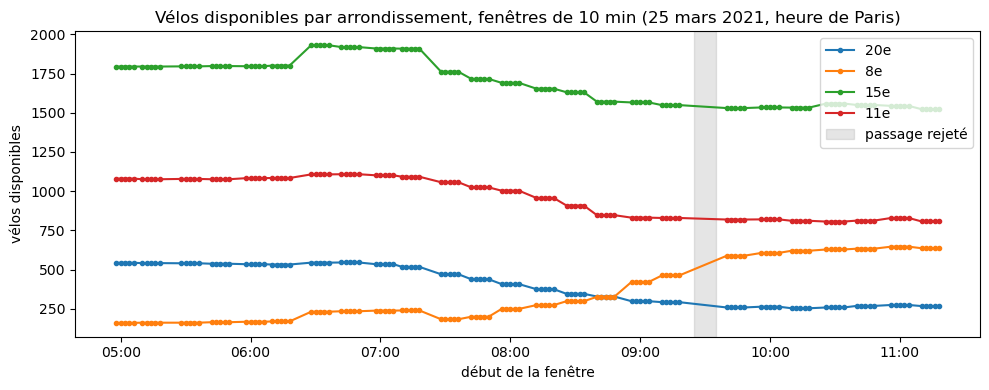

In [13]:
ARRONDISSEMENTS_TRACES = {20: "20e", 8: "8e", 15: "15e", 11: "11e"}
courbes = (flux_arrondissements.filter(F.col("arrondissement").isin(list(ARRONDISSEMENTS_TRACES)))
           .select("fenetre_debut", "arrondissement", "velos_disponibles")
           .orderBy("fenetre_debut").toPandas())             # ~500 lignes
courbes["fenetre_debut"] = courbes["fenetre_debut"] + pd.Timedelta(hours=1)    # heure de Paris (UTC+1)

fig, ax = plt.subplots(figsize=(10, 4))
for code_arr, libelle in ARRONDISSEMENTS_TRACES.items():
    c = courbes[courbes["arrondissement"] == code_arr]
    ax.plot(c["fenetre_debut"], c["velos_disponibles"], marker=".", linestyle="-", label=libelle)
debut_rejete = HORAIRES[PASSAGE_REJETE] + pd.Timedelta(hours=1)
ax.axvspan((debut_rejete - pd.Timedelta(minutes=10)).tz_localize(None), debut_rejete.tz_localize(None),
           color="grey", alpha=0.2, label="passage rejeté")
ax.set_title("Vélos disponibles par arrondissement, fenêtres de 10 min (25 mars 2021, heure de Paris)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_xlabel("début de la fenêtre")
ax.set_ylabel("vélos disponibles")
ax.legend()
plt.tight_layout()
plt.show()

Les courbes montrent la **pointe du matin** du jeudi 25 mars :

- le **8e** (bureaux) passe de 160 à 640 vélos disponibles entre 8 h et 10 h : on y arrive à vélo ;
- le **20e** (résidentiel, en hauteur) tombe de 540 à 260 vélos, et le **11e** de 1 080 à 810 : on en part ;
- le **15e**, le plus grand parc, perd lui aussi près de 300 vélos.

Chaque palier correspond à un passage du collecteur : un passage alimente les cinq fenêtres glissantes qui le contiennent. La zone grisée (9 h 26 - 9 h 34, heure de Paris) n'a aucun point : c'est le passage rejeté, que le flux n'a jamais compté.

### Les alertes

Pour vérifier la table `alertes`, on la recalcule en batch par un autre chemin : `LAG` sur les relevés de
chaque station (sans le passage rejeté), en gardant les paires de **relevés successifs à zéro**, espacés de
moins de 20 minutes (deux fenêtres adjacentes de 10 minutes ne peuvent pas contenir des relevés plus
éloignés). On ne compare que les relevés dont toutes les fenêtres ont été finalisées par le flux.

In [14]:
alertes = spark.read.format("delta").load(str(DELTA_ALERTES))
limite = (watermark_final - pd.Timedelta(FENETRE)).to_pydatetime()
par_station = Window.partitionBy("station_id").orderBy("horodatage")
paires_batch = (releves_batch.filter(F.col("horodatage") != F.lit(t_rejete))
                .withColumn("releve_precedent", F.lag("horodatage").over(par_station))
                .withColumn("velos_precedents", F.lag("velos_disponibles").over(par_station))
                .filter("velos_disponibles = 0 AND velos_precedents = 0")
                .filter(F.col("horodatage") - F.col("releve_precedent") < F.expr("INTERVAL 20 MINUTES"))
                .select("station_id", F.col("releve_precedent").alias("premier_releve_vide"),
                        F.col("horodatage").alias("second_releve_vide")))
cles_alerte = ["station_id", "premier_releve_vide", "second_releve_vide"]
flux_comparables = alertes.filter(F.col("second_releve_vide") <= F.lit(limite)).select(*cles_alerte)
batch_comparables = paires_batch.filter(F.col("second_releve_vide") <= F.lit(limite))

n_alertes, n_comparables = alertes.count(), flux_comparables.count()
print(f"{n_alertes} alertes, dont {n_comparables} sur des relevés antérieurs à {limite:%H:%M}")
print("Paires batch absentes du flux :", batch_comparables.exceptAll(flux_comparables).count(),
      "| alertes du flux absentes du batch :", flux_comparables.exceptAll(batch_comparables).count())
assert batch_comparables.exceptAll(flux_comparables).count() == 0
assert flux_comparables.exceptAll(batch_comparables).count() == 0
assert alertes.groupBy("station_id", "second_releve_vide").count().filter("count > 1").count() == 0

365 alertes, dont 365 sur des relevés antérieurs à 10:20


Paires batch absentes du flux : 0 | alertes du flux absentes du batch : 0


Les stations qui déclenchent le plus d'alertes, et le nombre de stations en alerte au fil de la matinée :

In [15]:
(alertes.groupBy("station_id", "nom_station", "arrondissement")
 .agg(F.count("*").alias("alertes"),
      F.date_format(F.from_utc_timestamp(F.min("premier_releve_vide"), "Europe/Paris"), "HH:mm").alias("vide_des"),
      F.date_format(F.from_utc_timestamp(F.max("second_releve_vide"), "Europe/Paris"), "HH:mm").alias("encore_vide_a"))
 .orderBy(F.desc("alertes"), "station_id").show(12, truncate=False))

par_passage = (alertes.groupBy("second_releve_vide").agg(F.count("*").alias("stations_en_alerte"))
               .orderBy("second_releve_vide").toPandas())
par_passage["heure_paris"] = (pd.to_datetime(par_passage["second_releve_vide"]) + pd.Timedelta(hours=1)).dt.strftime("%H:%M")
print(par_passage.set_index("heure_paris")["stations_en_alerte"].to_string())

+----------+--------------------------------------+--------------+-------+--------+-------------+
|station_id|nom_station                           |arrondissement|alertes|vide_des|encore_vide_a|
+----------+--------------------------------------+--------------+-------+--------+-------------+
|45003     |11 Novembre 1918 - 8 Mai 1945         |45            |23     |05:07   |11:19        |
|21951     |Place Centrale                        |21            |16     |06:50   |11:19        |
|20019     |Place du Maquis du Vercors            |20            |12     |05:07   |11:19        |
|23701     |Parvis Robert Schuman - Roger Salengro|23            |12     |07:51   |11:19        |
|22203     |Tertres - Fontaine                    |22            |11     |08:05   |11:19        |
|22603     |Place de la Division Leclerc          |22            |11     |05:07   |07:51        |
|100043    |Saint-Germain-des-Prés                |6             |11     |05:07   |07:51        |
|7014      |Saint-Fr

heure_paris
05:19    18
05:36    17
05:51    15
06:07    15
06:19    15
06:36     8
06:50     8
07:06     9
07:19     7
07:36     6
07:51    12
08:05     9
08:20    14
08:34     9
08:49    10
09:05     9
09:19    19
10:04    20
10:19    25
10:35    30
10:49    32
11:05    30
11:19    28


Le flux a produit **365 alertes**, et le calcul batch par `LAG` retrouve **exactement les mêmes paires de relevés**. La définition par fenêtres adjacentes équivaut donc bien à « vide à deux passages successifs ». La table ne contient aucun doublon, même si plusieurs paires de fenêtres confirment souvent le même relevé.

- Le nombre de stations en alerte suit la journée : environ 15 au petit matin (stations restées vides depuis la nuit), une dizaine vers 7 h, puis **une trentaine en fin de matinée**.
- On voit aussi l'effet du passage rejeté : aucune alerte n'est datée de 9 h 35 ou 9 h 49 (heure de Paris). Sans le relevé de 9 h 35, ceux de 9 h 20 et de 9 h 49 sont séparés de 30 minutes : ils ne tombent plus dans deux fenêtres adjacentes. Une donnée perdue fait donc aussi rater des alertes : c'est le prix du watermark.
- Les stations les plus souvent en alerte sont des stations de banlieue vides toute la matinée (codes 45, 21, 23 et 22), mais aussi des stations du centre vidées tôt puis réapprovisionnées : Saint-Germain-des-Prés et Saint-François-Xavier ne sont plus en alerte après 8 h. Place du Maquis du Vercors, dans le 20e, rappelle les ruptures du matin sur les hauteurs vues à la question 1 du carnet 03.

## 10. Reprise depuis le checkpoint

On arrête les deux requêtes, puis on relance `flux_arrondissements` **avec le même checkpoint**. Spark
y relit la liste des fichiers déjà traités, l'état des fenêtres ouvertes et le watermark : il ne relit
rien, et n'écrit aucune ligne de plus dans la table Delta (garantie *exactly-once* du sink Delta, qui
note dans son journal le numéro du dernier lot écrit).

In [16]:
for requete in REQUETES:
    requete.stop()
lignes_avant = flux_arrondissements.count()
version_avant = spark.sql(f"DESCRIBE HISTORY delta.`{DELTA_FLUX_ARRONDISSEMENTS}`").agg(F.max("version")).first()[0]

reprise = (fenetres_arrondissement(releves_flux).writeStream
           .queryName("flux_arrondissements_reprise")
           .format("delta").outputMode("append")
           .option("checkpointLocation", str(CHECKPOINTS / "arrondissements"))
           .start(str(DELTA_FLUX_ARRONDISSEMENTS)))
reprise.processAllAvailable()
lues_reprise = sum(p["numInputRows"] for p in reprise.recentProgress)
reprise.stop()

lignes_apres = spark.read.format("delta").load(str(DELTA_FLUX_ARRONDISSEMENTS)).count()
print(f"Lignes lues à la reprise : {lues_reprise} | lignes dans la table : {lignes_avant} -> {lignes_apres}")
assert lues_reprise == 0 and lignes_apres == lignes_avant

Lignes lues à la reprise : 0 | lignes dans la table : 5250 -> 5250


Le journal Delta de la table montre un commit `STREAMING UPDATE` par micro-lot ayant émis des fenêtres,
avec le numéro de lot (`epochId`) et l'identifiant de la requête : c'est ce qui permet au sink de
reconnaître un lot déjà écrit.

In [17]:
historique = spark.sql(f"DESCRIBE HISTORY delta.`{DELTA_FLUX_ARRONDISSEMENTS}`")
(historique.groupBy("operation").agg(F.count("*").alias("commits"),
                                       F.sum(F.col("operationMetrics.numOutputRows").cast("long")).alias("lignes"))
 .show(truncate=False))
historique.select("version", "operation", "operationParameters.epochId",
                  "operationMetrics.numOutputRows").orderBy(F.desc("version")).show(5, truncate=False)

+----------------+-------+------+
|operation       |commits|lignes|
+----------------+-------+------+
|STREAMING UPDATE|30     |5250  |
+----------------+-------+------+

+-------+----------------+-------+-------------+
|version|operation       |epochId|numOutputRows|
+-------+----------------+-------+-------------+
|29     |STREAMING UPDATE|29     |210          |
|28     |STREAMING UPDATE|28     |210          |
|27     |STREAMING UPDATE|27     |210          |
|26     |STREAMING UPDATE|26     |210          |
|25     |STREAMING UPDATE|25     |210          |
+-------+----------------+-------+-------------+
only showing top 5 rows



## 11. Mesures et bilan

In [18]:
lots_donnees = prog_arrondissements[prog_arrondissements["lignes_lues"] > 0]
enregistrer_mesures("04_streaming", {
    "passages_rejoues": len(HORAIRES),
    "releves_rejoues": int(passages["releves"].sum()),
    "duree_flux_s": round(duree_flux, 1),
    "micro_lots_arrondissements": len(prog_arrondissements),
    "micro_lots_stations": len(prog_stations),
    "duree_moyenne_lot_donnees_ms": round(float(lots_donnees["duree_ms"].mean())),
    "lignes_rejetees_watermark": resultats_retard,
    "fenetres_arrondissement_emises": lignes_avant,
    "alertes": n_alertes,
})
print(json.dumps(json.loads(MESURES_JSON.read_text(encoding="utf-8"))["04_streaming"], indent=2))

{
  "passages_rejoues": 28,
  "releves_rejoues": 38276,
  "duree_flux_s": 154.3,
  "micro_lots_arrondissements": 31,
  "micro_lots_stations": 29,
  "duree_moyenne_lot_donnees_ms": 2271,
  "lignes_rejetees_watermark": {
    "flux_arrondissements": 210,
    "flux_stations": 6835
  },
  "fenetres_arrondissement_emises": 5250,
  "alertes": 365
}


## Bilan du Jour 2 après-midi

| Élément | Résultat |
|---|---|
| Simulateur | 28 passages (38 276 relevés) rejoués en une minute, fichiers JSON écrits de façon atomique ; retards introduits par `--retard` |
| Source | `readStream` JSON, schéma explicite, `maxFilesPerTrigger = 1` |
| Fenêtres | 10 minutes, glissement de 2 minutes, watermark de 20 minutes |
| Sink Delta | `flux_arrondissements` en mode *append* : 5 250 lignes, un commit par micro-lot |
| Alertes | `foreachBatch` (écriture idempotente + `MERGE`) : 365 alertes, identiques au calcul batch |
| Donnée tardive | passage en retard de 15 min accepté ; passage en retard d'une heure rejeté (210 et 6 835 lignes après agrégation partielle) ; contre-épreuve batch : seules ses 5 fenêtres manquent |
| Reprise | relance sur le même checkpoint : 0 ligne relue, 0 ligne écrite en double |

- **Latence** : un micro-lot de 1 367 relevés prend environ 2,3 s, presque entièrement en coûts fixes (planification, état sur 8 partitions, commit Delta). `flux_stations`, qui ajoute une jointure et un `MERGE` par lot, va environ deux fois moins vite et a fini avec plus d'une minute de retard sur le simulateur. Structured Streaming vise une latence de l'ordre de la seconde, pas de la milliseconde : c'est l'un des points du bilan d'architecture du carnet 06.
- **Limite du rejeu** : il ne couvre qu'une matinée, et la cadence réelle du collecteur (un passage toutes les 15 minutes environ) est plus lente que la fenêtre de 10 minutes : une fenêtre contient au plus un passage.

On arrête la session.

In [19]:
spark.stop()
print("SparkSession arrêtée.")

SparkSession arrêtée.
